In [1]:
import matplotlib.pyplot as plt
import torch
import torchvision
import torchvision.transforms as T
from torchvision.models.resnet import ResNet50_Weights, resnet50
from torchlake.common.datasets.images import SubsetImageFolder

from torchlake.common.constants import IMAGENET_MEAN, IMAGENET_STD
from torchlake.common.utils.convert import img_tensor_to_np
from torchlake.common.utils.numerical import imagenet_denormalization
from torchlake.explanation.models.grad_cam import GradCAM
from torchlake.common.datasets.imagenet import IMAGENET_CLASS_NAMES

# data

In [2]:
DEVICE = "cuda:0"

In [3]:
IMAGE_SIZE = 224

In [4]:
dataset = torchvision.datasets.ImageFolder("../../data/animal10")
# dataset = SubsetImageFolder("../../data/animal10", ("cavallo",))

In [5]:
transform = T.Compose(
    [
        T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

# model

In [6]:
model = resnet50(weights=ResNet50_Weights.DEFAULT)

# evaluation

In [7]:
explainer = GradCAM(model).to(DEVICE)

In [8]:
explainer.set_activation_layer("layer4")

In [31]:
idx = 8000
img, label = dataset[idx]
img = transform(img)
img = img.unsqueeze(0)
img = img.to(DEVICE)

model.eval()
with torch.no_grad():
    output = model(img).argmax(-1)

importance = explainer(img, counterfactual=False)
counterfactual_importance = explainer(img, counterfactual=True)

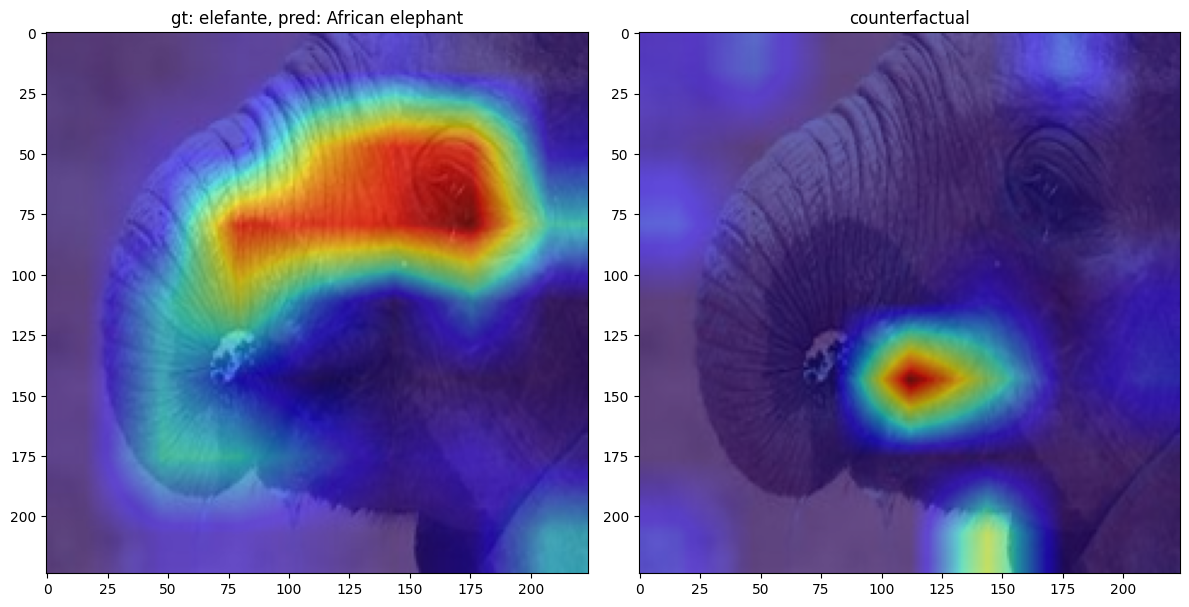

In [35]:
fig, axes = plt.subplots(1, 2)
fig.set_figheight(6)
fig.set_figwidth(12)

plt.subplot(1, 2, 1)
plt.title(f"gt: {dataset.classes[label]}, pred: {IMAGENET_CLASS_NAMES[output.item()]}")
plt.imshow(img_tensor_to_np(imagenet_denormalization(img.detach().cpu())))
plt.imshow(img_tensor_to_np(importance.detach().cpu()), cmap="jet", alpha=0.6)

plt.subplot(1, 2, 2)
plt.title("counterfactual")
plt.imshow(img_tensor_to_np(imagenet_denormalization(img.detach().cpu())))
plt.imshow(
    img_tensor_to_np(counterfactual_importance.detach().cpu()), cmap="jet", alpha=0.6
)

plt.tight_layout()